# TVOG of a maturity guarantee under G2++ scenarios

`CashValue_ME_G2PP` is lifelib's savings model `CashValue_ME_EX4` with its economic inputs
taken from the space `ESG`, a copy of BasicG2PP's `G2PP` space. ESG reads
`g2pp_input.xlsx` in the library folder. Its scenario 0 is the certainty-equivalent (CE)
scenario, which follows the initial forward curve, so one run gives both terms of

TVOG = mean of the present values over the stochastic scenarios − the present value in the CE scenario.

This notebook shows the model points, the TVOG of the guaranteed minimum accumulation
benefit (GMAB) on the delivered input, how it depends on the bond fund the account value
is invested in, and how the Monte Carlo results compare with the closed form.

Click the badge below to run this notebook online on Google Colab. You need a Google account and need to be logged in to it to run this notebook on Google Colab.
[![Run on Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lifelib-dev/lifelib/blob/current/lifelib/libraries/economic/g2pp-tvog.ipynb)


The next code cell below is relevant only when you run this notebook on Google Colab. It installs lifelib and creates a copy of the library for this notebook.

In [1]:
import sys, os

if 'google.colab' in sys.modules:
    lib = 'economic'; lib_dir = '/content/'+ lib
    if not os.path.exists(lib_dir):
        !pip install lifelib
        import lifelib; lifelib.create(lib, lib_dir)
        
    %cd $lib_dir

In [2]:
import matplotlib.pyplot as plt
import modelx as mx
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from modelx.core.errors import FormulaError
from scipy import stats

model = mx.read_model("CashValue_ME_G2PP")
proj, esg = model.Projection, model.ESG
T = 120                                   # every model point matures in month 120
n_scen = len(esg.scen_index())
print(f"{n_scen - 1:,} stochastic scenarios plus the CE scenario; fund {esg.fund_id()}")

1,000 stochastic scenarios plus the CE scenario; fund BOND_MIX


In [3]:
# Chart style: light-mode tokens of the reference palette, one categorical slot per fund
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
FUND_COLORS = {"CASH": "#2a78d6", "BOND_MIX": "#1baf7a", "BOND_10Y": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
    "legend.labelcolor": INK_2, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "font.size": 9.5,
})

## Model points

All nine model points are 10-year policies: 100 policies with a sum assured of 500,000
each. Points 1, 2, 5, 6 and 9 pay a single premium. For them, the account value after the
premium, AV0, divided by the present value of the sum assured, SA · P(0, 10), shows how far
the guarantee is in the money: below 1 it pays in the CE scenario. Points 3, 4, 7 and 8
pay level premiums every month, build up account values far above the sum assured, and
their GMAB costs nothing.

In [4]:
mps = proj.model_point_table_ext()
sa = (proj.sum_assured() * proj.pols_maturity(T))[::n_scen]
av0 = proj.av_at(0, "BEF_FEE")[::n_scen]
is_single = (mps["premium_type"] == "SINGLE").to_numpy()
points = pd.DataFrame({
    "premium type": mps["premium_type"], "premium per policy": mps["premium_pp"], "SA": sa,
    "AV0": np.where(is_single, av0, np.nan),
    "AV0 / (SA P(0,10))": np.where(is_single, av0 / (sa * esg.mkt_zcb(T)), np.nan).round(3),
}, index=mps.index)
single = points.index[is_single].tolist()
points

,premium type,premium per policy,SA,AV0,"AV0 / (SA P(0,10))"
point_id,,,,,
1,SINGLE,500000,50000000.0,50000000.0,1.267
2,SINGLE,475000,50000000.0,47500000.0,1.203
3,LEVEL,450000,50000000.0,NaN,NaN
4,LEVEL,425000,50000000.0,NaN,NaN
5,SINGLE,400000,50000000.0,40000000.0,1.013
6,SINGLE,375000,50000000.0,37500000.0,0.950
7,LEVEL,350000,50000000.0,NaN,NaN
8,LEVEL,325000,50000000.0,NaN,NaN
9,SINGLE,300000,50000000.0,30000000.0,0.760


## TVOG on the delivered input

`result_tvog()` gives, for each model point, the present value in the CE scenario, the
mean over the stochastic scenarios, their difference (the TVOG) and the standard error of
the mean from antithetic pairs. For the GMAB cost:

In [5]:
tvog = proj.result_tvog()
tvog["GMAB"].round(0)

,CE,mean,TVOG,SE
point_id,,,,
1,0.0,0.0,0.0,0.0
2,0.0,618.0,618.0,453.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,0.0,771177.0,771177.0,31328.0
6,1970018.0,2255066.0,285048.0,21916.0
7,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0
9,9470018.0,9467934.0,-2084.0,10635.0


The GMDB costs nothing because EX4 has no mortality. The TVOG of the present value of net
cash flows is the GMAB's TVOG with the opposite sign, plus Monte Carlo noise. Premium
loads, commissions and expenses are fixed amounts, and their mean deflated value equals
their CE value only up to sampling error. The noise is largest for the level-premium points
3 and 7, whose premiums carry 10% loads; on the delivered input it is within one standard
error:

In [6]:
pd.DataFrame({"GMAB TVOG": tvog["GMAB"]["TVOG"],
              "net cash flow TVOG": tvog["net cash flow"]["TVOG"],
              "sum (noise)": tvog["GMAB"]["TVOG"] + tvog["net cash flow"]["TVOG"],
              "net cash flow SE": tvog["net cash flow"]["SE"]}).round(0)

,GMAB TVOG,net cash flow TVOG,sum (noise),net cash flow SE
point_id,,,,
1,0.0,-34.0,-34.0,45.0
2,618.0,-652.0,-34.0,456.0
3,0.0,16900.0,16900.0,22170.0
4,0.0,-34.0,-34.0,45.0
5,771177.0,-771211.0,-34.0,31330.0
6,285048.0,-285082.0,-34.0,21924.0
7,0.0,13137.0,13137.0,17234.0
8,0.0,-34.0,-34.0,45.0
9,-2084.0,2050.0,-34.0,10661.0


## TVOG by fund

The ESG takes the fund from `fund_id` in the workbook. To compare funds without editing
the workbook, the next cell overrides the value of ESG's `fund_id` cell
(`esg.fund_id[()] = ...`), which recalculates everything that depends on it, and restores
the workbook's value at the end with `esg.fund_id.clear_all()`.

For an all-cash fund and for a fund holding a single maturity, `formula_gmab_g2pp(t)` gives
the exact GMAB cost, from the variance s² of the log growth of the account value. A mix
of maturities has no exact closed form.

In [7]:
funds = ["CASH", "BOND_MIX", "BOND_10Y"]
p_T = esg.mkt_zcb(T)
results = {}
for fund in funds:
    esg.fund_id[()] = fund
    gmab = proj.result_tvog()["GMAB"].loc[single]
    try:
        formula, s2 = proj.formula_gmab_g2pp(T), esg.fund_logvar(T)
    except FormulaError:
        formula, s2 = pd.Series(np.nan, index=single), np.nan
    results[fund] = {"gmab": gmab, "formula": formula, "s2": s2}
esg.fund_id.clear_all()
print(f"fund restored to {esg.fund_id()}")
for fund in funds:
    s2 = results[fund]["s2"]
    note = f"{np.sqrt(s2 / 10):.2%} a year" if s2 == s2 else "no closed form"
    print(f"{fund:9s} volatility of the account value's log growth over 10 years: {note}")

fund restored to BOND_MIX
CASH      volatility of the account value's log growth over 10 years: 3.39% a year
BOND_MIX  volatility of the account value's log growth over 10 years: no closed form
BOND_10Y  volatility of the account value's log growth over 10 years: 3.31% a year


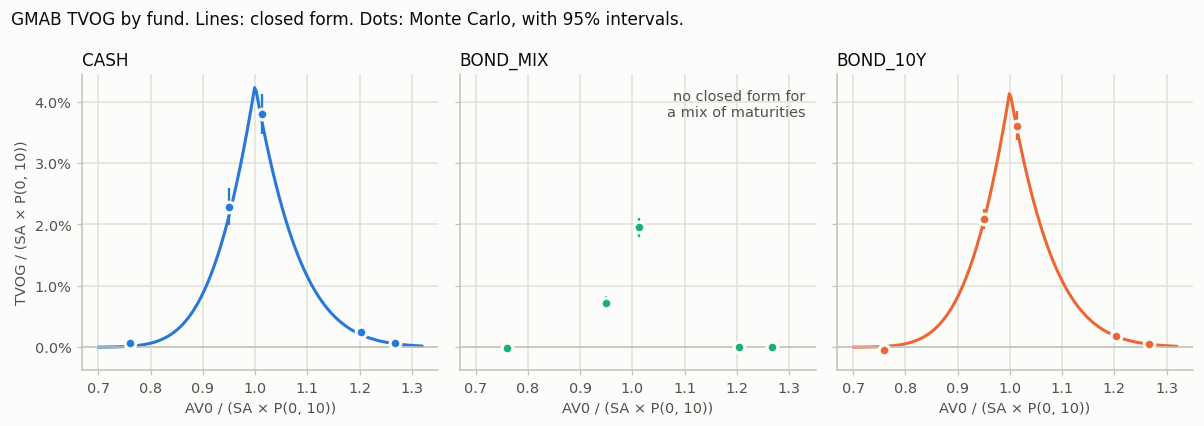

In [8]:
moneyness = points.loc[single, "AV0 / (SA P(0,10))"].to_numpy()
unit = (sa * p_T)[[p - 1 for p in single]]           # SA P(0,10) of each point
grid = np.linspace(0.7, 1.32, 200)


def closed_form_tvog(r, s2):
    """TVOG per unit of SA P(0,T) at moneyness r = AV0 / (SA P(0,T))."""
    s = np.sqrt(s2)
    d1 = (-np.log(r) + s2 / 2) / s
    return stats.norm.cdf(d1) - r * stats.norm.cdf(d1 - s) - np.maximum(1 - r, 0)


fig, axes = plt.subplots(1, len(funds), figsize=(11, 3.9), sharex=True, sharey=True)
for ax, fund in zip(axes, funds):
    color, res = FUND_COLORS[fund], results[fund]
    gmab = res["gmab"]
    if res["s2"] == res["s2"]:
        ax.plot(grid, closed_form_tvog(grid, res["s2"]), color=color)
    else:
        ax.text(0.97, 0.95, "no closed form for\na mix of maturities", transform=ax.transAxes,
                ha="right", va="top", color=INK_2)
    ax.errorbar(moneyness, gmab["TVOG"] / unit, yerr=1.96 * gmab["SE"] / unit, fmt="o",
                color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2,
                elinewidth=1.5, capsize=0, zorder=3)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title(fund)
    ax.set_xlabel("AV0 / (SA × P(0, 10))")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
axes[0].set_ylabel("TVOG / (SA × P(0, 10))")
fig.suptitle("GMAB TVOG by fund. Lines: closed form. Dots: Monte Carlo, with 95% intervals.",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

In [9]:
table = pd.concat({fund: pd.DataFrame({
    "TVOG": results[fund]["gmab"]["TVOG"],
    "SE": results[fund]["gmab"]["SE"],
    "closed-form TVOG": results[fund]["formula"] - results[fund]["gmab"]["CE"],
}) for fund in funds}, axis=1)
table.round(0)

CASH                            BOND_MIX                            \
        TVOG       SE closed-form TVOG      TVOG       SE closed-form TVOG   
1    30139.0  11152.0          22775.0       0.0      0.0              NaN   
2    95945.0  19976.0          79078.0     618.0    453.0              NaN   
5  1499775.0  66074.0        1445854.0  771177.0  31328.0              NaN   
6   903679.0  61062.0         843310.0  285048.0  21916.0              NaN   
9    24362.0  18318.0           6112.0   -2084.0  10635.0              NaN   

    BOND_10Y                            
        TVOG       SE closed-form TVOG  
1    20830.0   7190.0          19166.0  
2    74277.0  13677.0          69855.0  
5  1423709.0  46774.0        1407136.0  
6   820980.0  32955.0         809690.0  
9   -18990.0  21597.0           4931.0

The closed form runs through the Monte Carlo results for the all-cash fund and the
10-year bond fund, within their sampling error. Those two curves are almost the same: over ten
years, holding 10-year zero-coupon bonds and rolling them every month makes the account
value about as volatile as holding cash. The mixed fund, 20% cash, 30% 5-year and 50%
10-year bonds, makes the guarantee much cheaper. Its value falls less when rates rise, and
higher reinvestment returns afterwards make up for the fall, so the account value at
maturity is less uncertain.

The library's test suite checks these results more tightly: in every scenario the GMAB cost equals
D(T) · (SA − AV0 · fund growth)⁺ recomputed from the ESG paths, to 1e-10 of the sum
assured (`tests/test_cashvalue_me_g2pp.py`).